In [1]:
import os, sys

sys.path.append(os.path.dirname(os.path.dirname(os.path.abspath("__file__"))))
from nbafuns import *
from nba_api.stats.endpoints import leaguedashplayerptshot, playerdashptshots, leaguedashteamptshot

data_DIR = "../data/synergy/"

In [2]:
dfa = []
seasons = range(2015,2025)
for season in seasons:
    df1 = pd.read_parquet(data_DIR+f"NBA_Synergy_T_Cum_{season}.parquet")
    dfa.append(df1)
df2 = pd.concat(dfa)

In [7]:
df3 = df2.copy()
df3.columns = map(str.lower,df3.columns)
df3 = df3.query("type_grouping == 'Offensive'").reset_index(drop=True)

In [33]:
play_types = df3["play_type"].unique()
play_types

array(['Transition', 'Isolation', 'PRBallHandler', 'PRRollMan', 'Postup',
       'Spotup', 'Handoff', 'Cut', 'OffScreen', 'OffRebound', 'Misc'],
      dtype=object)

In [13]:
pt = play_types[0]
df4 = df3.query(f"play_type == '{pt}'").reset_index(drop=True)

In [23]:
df4 = df3.groupby("play_type")[["poss","ft_poss_pct"]].mean().reset_index()

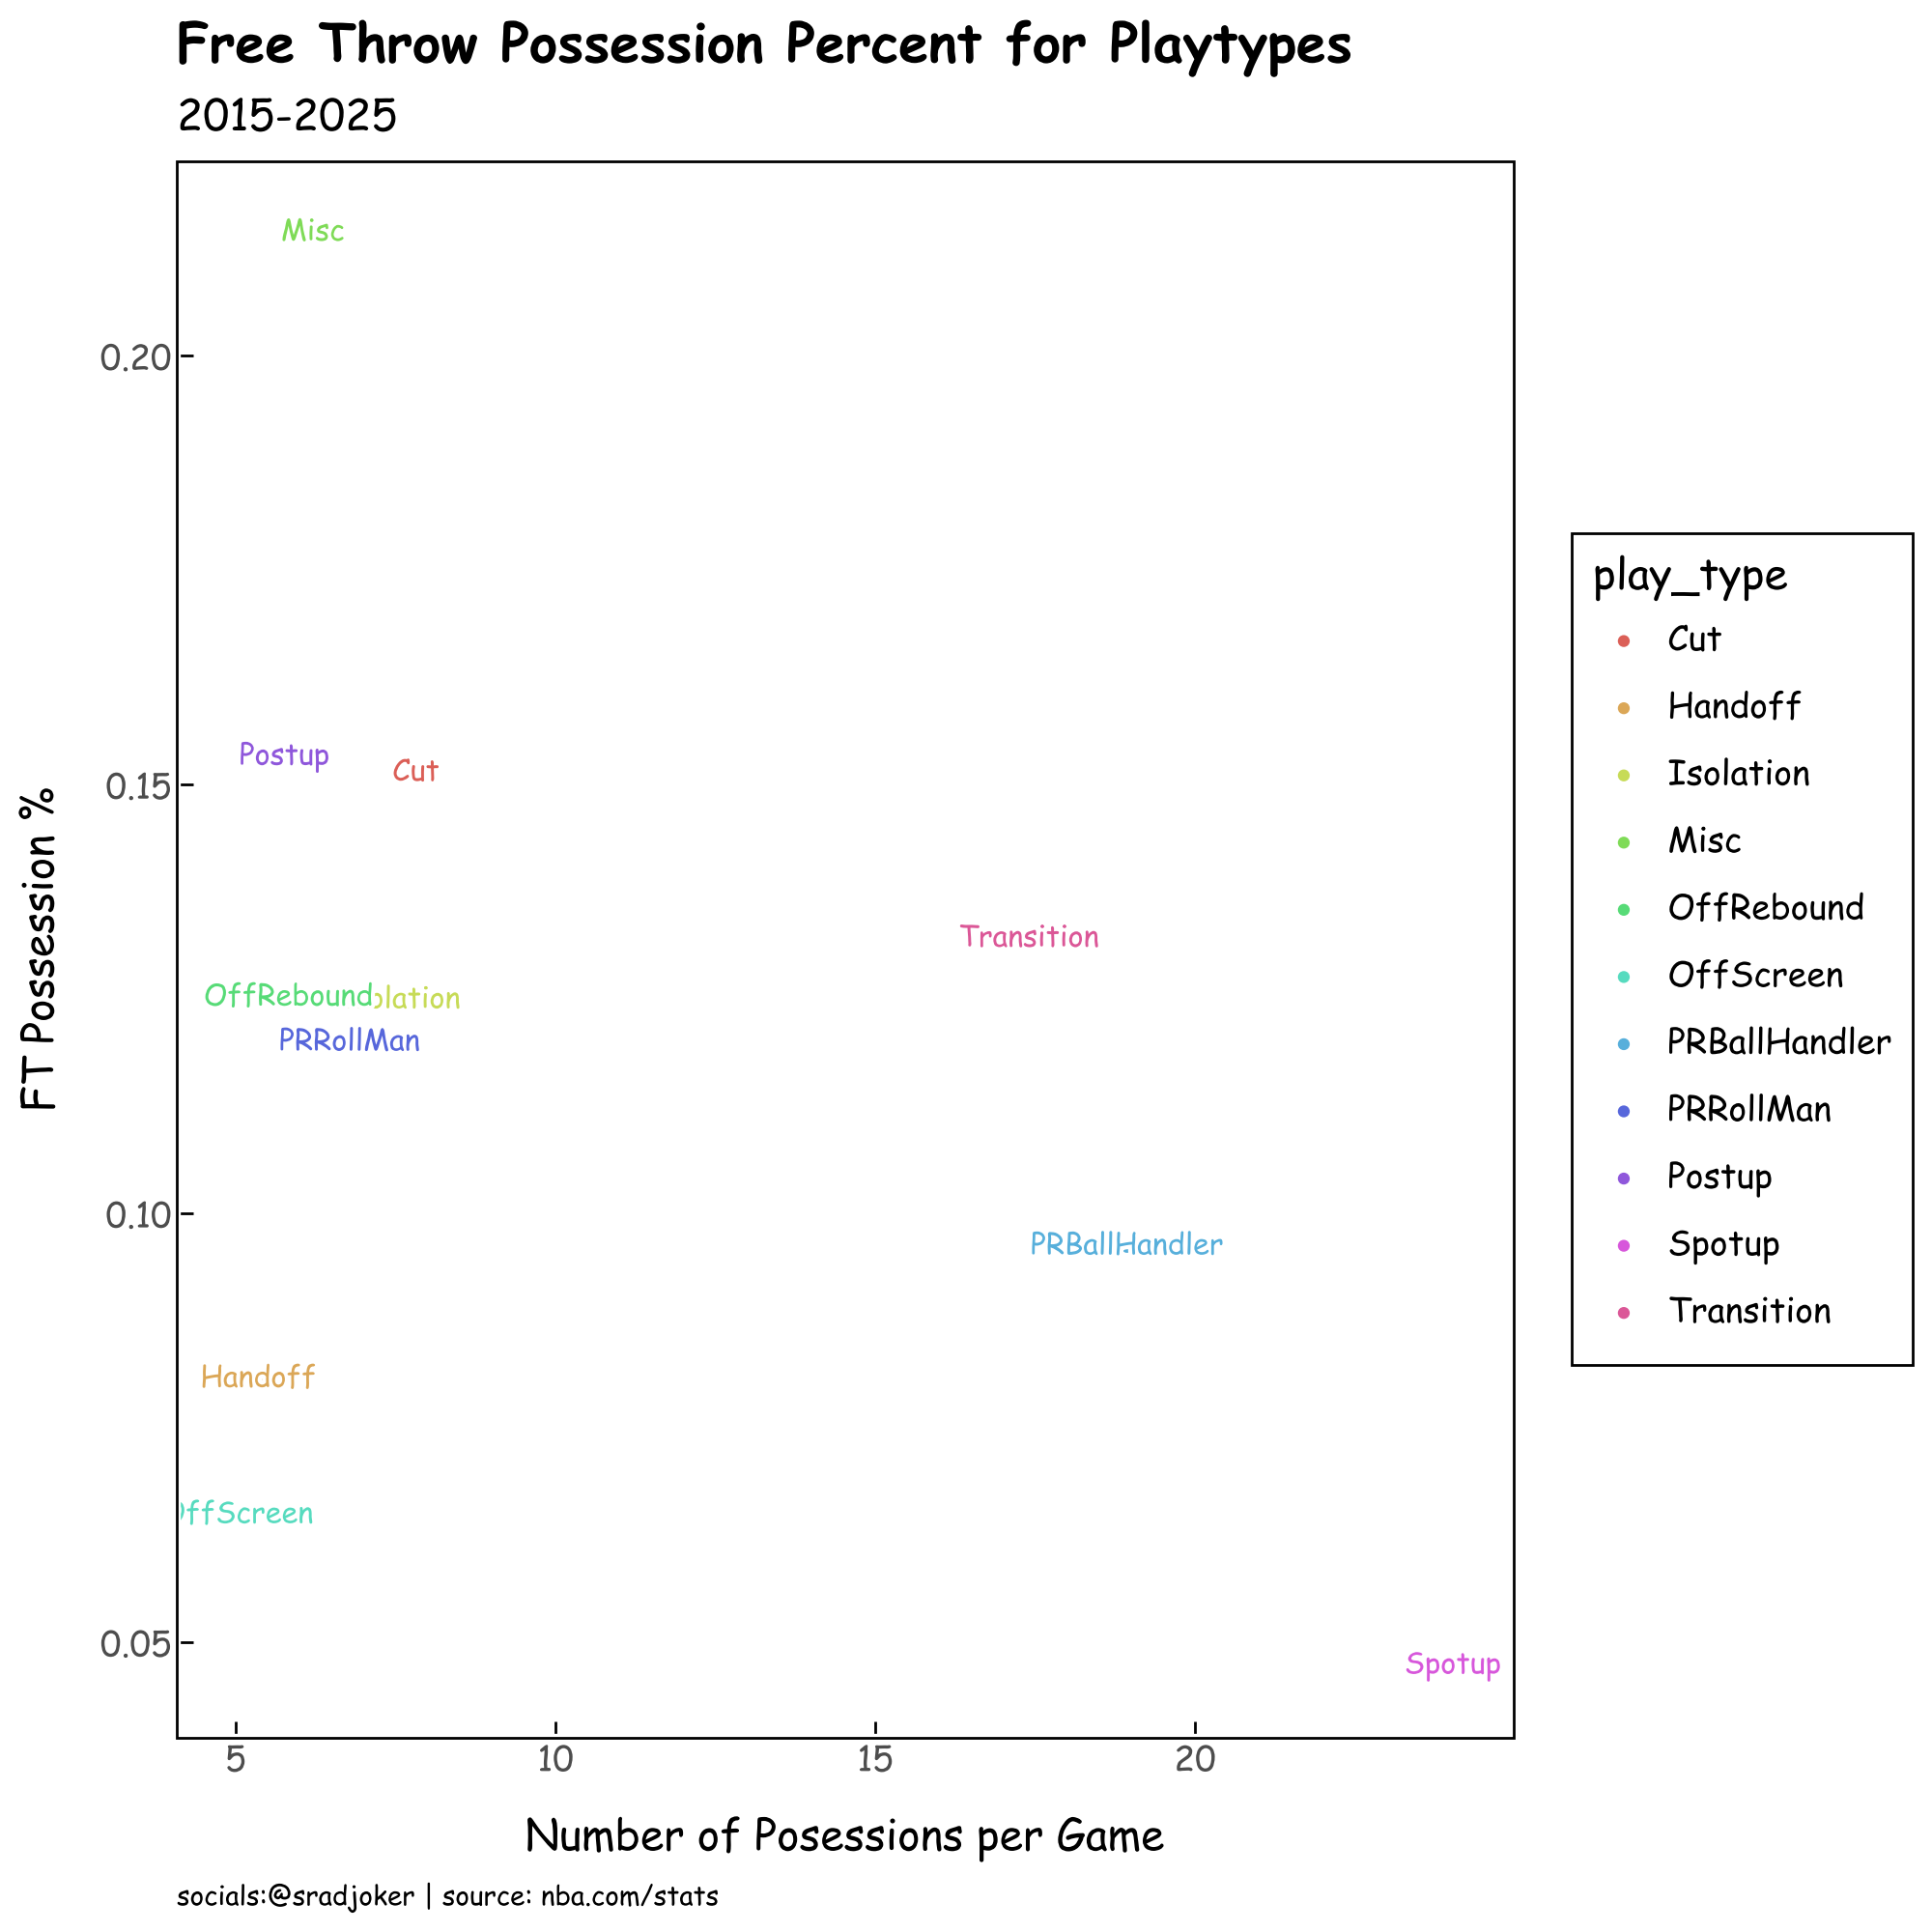

In [42]:
p = (
    ggplot(df4)
    + aes(x="poss",y="ft_poss_pct",color="play_type", group="play_type")
    + geom_point()
    + geom_text(aes(label="play_type"),show_legend=False)
    # + geom_smooth(method="lm",se=False)
    + theme_idv
    + theme(
        # plot_title=element_text(size=18),
        figure_size=(10,10)
    )
    + labs(
        title="Free Throw Possession Percent for Playtypes",
        subtitle="2015-2025",
        x="Number of Posessions per Game",
        y="FT Possession %",
    )
    + pnba
)
p